# Minimal model of transitive inference task
The purpose of this notebook is to make the smallest model possible that solves the transitive inference task.

## Imports

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np

import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import matplotlib.cm as cm
import seaborn as sns

import string
from tqdm import tqdm

from relational_attention.tasks import TransitiveInferenceDataset

In [2]:
torch.manual_seed(42)

## Build task

In [3]:
# Parameters
num_samples = 1000
num_items = 10

In [4]:
# Training task
dataset = TransitiveInferenceDataset(num_samples=num_samples, num_items=num_items, train=False, all=True)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

In [5]:
dataset.data[0], dataset.labels[0]

(tensor([[0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 1., 0., 0., 0., 0., 0.]]),
 tensor(1.))

## Design model

In [6]:
class RelationalAttentionHead(nn.Module):
    def __init__(self, embed_dim, head_dim):
        super().__init__()
        # Initialize weights
        self.W_q = nn.Linear(embed_dim, head_dim, bias=False)
        self.W_k = nn.Linear(embed_dim, head_dim, bias=False)

    def forward(self, x_1, x_2):
        """
        x_1: (batch, embed_dim)
        x_2: (batch, embed_dim)
        returns: (batch, seq_len, head_dim)
        """
        Q = self.W_q(x_2)                            # (B, D)
        K = self.W_k(x_1)                            # (B, D)

        # Compute attention scores over the *learned* Value slots
        attn_weights = torch.matmul(Q, K.transpose(-2, -1)) / (K.size(-1) ** 0.5)  # (B, L, L)
        return attn_weights.flatten()

In [7]:
model = RelationalAttentionHead(num_items, 2)

## Train model

### Functions

In [8]:
def train_model(
    model,
    data_loader,
    optimizer=None,
    loss_fn=None,
    epochs=10,
    device=None,
    return_history=True,
    verbose=True,
):
    # Defaults
    device = device or next(model.parameters()).device
    optimizer = optimizer or torch.optim.Adam(model.parameters())
    loss_fn = loss_fn or torch.nn.BCEWithLogitsLoss()

    # Put model in training mode
    model.train()

    loss_history = []

    # Optionally wrap tqdm
    progress = range(epochs)
    if verbose:
        progress = tqdm(progress, desc="Training", total=epochs, leave=True)

    for epoch in progress:
        total_loss = 0.0

        for X, y in data_loader:
            X, y = X.to(device), y.to(device)
            optimizer.zero_grad()

            preds = model(X[:,0:1,:], X[:,1:2,:])
            loss = loss_fn(preds, y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(data_loader)
        loss_history.append(avg_loss)

        # Update progress bar if active
        if verbose:
            progress.set_postfix({"loss": f"{avg_loss:.4f}"})

    if verbose:
        progress.close()

    return loss_history if return_history else None


def evaluate_model(model, loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for X, y in loader:
            logits = model(X[:,0:1,:], X[:,1:2,:])
            preds = (torch.sigmoid(logits) > 0.5)

            correct += (preds == y).sum().item()
            total += y.size(0)

    return correct / total

### Training

In [9]:
lr = 1e-3
loss_fn = torch.nn.BCEWithLogitsLoss()
epochs = 500

In [10]:
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
loss = train_model(model, loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 500/500 [00:09<00:00, 50.39it/s, loss=0.0000]


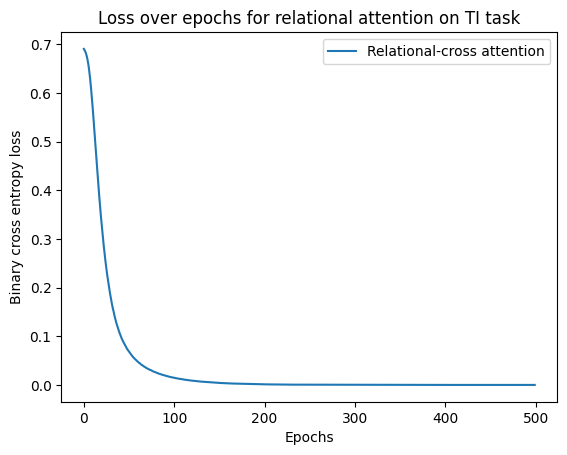

In [11]:
plt.plot(loss, label='Relational-cross attention')

plt.xlabel('Epochs')
plt.ylabel('Binary cross entropy loss')
plt.title('Loss over epochs for relational attention on TI task')
plt.legend()
plt.show()

## Visualize learned weights

In [12]:
Q_weights = model.W_q.weight.data
K_weights = model.W_k.weight.data

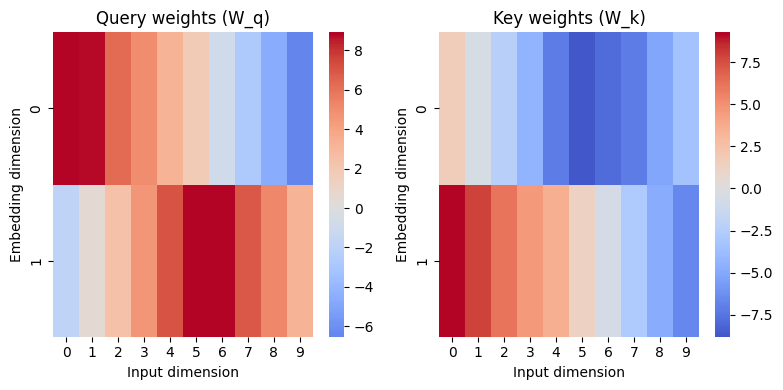

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
sns.heatmap(Q_weights, cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Query weights (W_q)")

sns.heatmap(K_weights, cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Key weights (W_k)")

for ax in axes:
    ax.set_xlabel("Input dimension")
    ax.set_ylabel("Embedding dimension")

plt.tight_layout()
plt.show()

In [14]:
def covariance(matrix):
    # subtract mean for proper covariance
    matrix_centered = matrix - matrix.mean(axis=0, keepdims=True)
    return np.cov(matrix_centered.T)  # (D, D)

In [15]:
cov_q = covariance(Q_weights)
cov_k = covariance(K_weights)

In [16]:
sim_qk = (Q_weights.T @ K_weights) / (K_weights.size(-1) ** 0.5)
sim_qk.shape

torch.Size([10, 10])

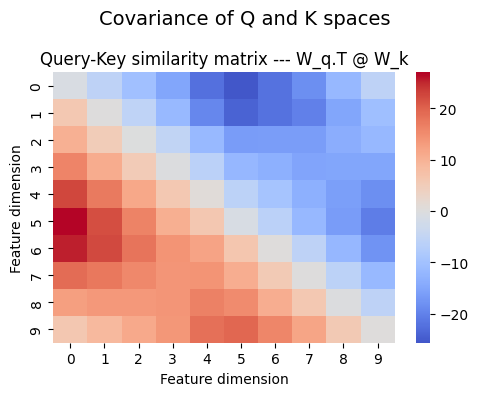

In [17]:
fig, ax = plt.subplots(1, 1, figsize=(5, 4))
sns.heatmap(sim_qk, cmap="coolwarm", center=0, ax=ax)
ax.set_title("Query-Key similarity matrix --- W_q.T @ W_k")

ax.set_xlabel("Feature dimension")
ax.set_ylabel("Feature dimension")

plt.suptitle("Covariance of Q and K spaces", fontsize=14)
plt.tight_layout()
plt.show()

### Plot arrow weighs

/var/folders/0v/sg01g0jd48j1x5lmw3jl63cc0000gn/T/ipykernel_31021/1922824150.py:10: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  lim = 1.1 * max(np.abs(Q_weights).max(), np.abs(K_weights).max())


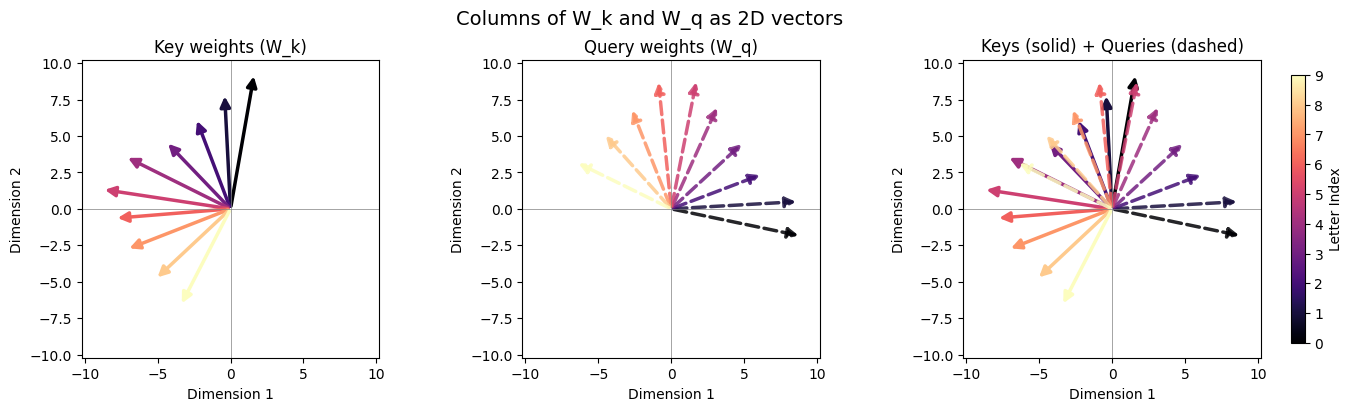

In [18]:
# Expect W_q, W_k as np.ndarray with shape (2, D)
assert Q_weights.shape[0] == 2 and K_weights.shape[0] == 2
assert Q_weights.shape[1] == K_weights.shape[1]
D = Q_weights.shape[1]

cmap = cm.magma
norm = Normalize(vmin=0, vmax=D - 1)

# Shared limits across all panels
lim = 1.1 * max(np.abs(Q_weights).max(), np.abs(K_weights).max())

fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)

# Common axis formatting helper (inline)
for ax in axes:
    ax.axhline(0, color="gray", linewidth=0.5)
    ax.axvline(0, color="gray", linewidth=0.5)
    ax.set_aspect("equal")
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")

# --- Panel 1: Keys only ---
ax = axes[0]
for i in range(D):
    color = cmap(norm(i))
    kx, ky = K_weights[:, i]
    ax.add_patch(
        FancyArrowPatch(
            (0, 0), (kx, ky),
            arrowstyle='-|>',
            mutation_scale=15,
            linewidth=2.5,
            color=color
        )
    )
ax.set_title("Key weights (W_k)")

# --- Panel 2: Queries only ---
ax = axes[1]
for i in range(D):
    color = cmap(norm(i))
    qx, qy = Q_weights[:, i]
    ax.add_patch(
        FancyArrowPatch(
            (0, 0), (qx, qy),
            arrowstyle='-|>',
            mutation_scale=15,
            linewidth=2.5,
            linestyle='--',
            color=color,
            alpha=0.85
        )
    )
ax.set_title("Query weights (W_q)")

# --- Panel 3: Keys + Queries ---
ax = axes[2]
for i in range(D):
    color = cmap(norm(i))

    # Keys (solid)
    kx, ky = K_weights[:, i]
    ax.add_patch(
        FancyArrowPatch(
            (0, 0), (kx, ky),
            arrowstyle='-|>',
            mutation_scale=15,
            linewidth=2.5,
            color=color
        )
    )

    # Queries (dashed)
    qx, qy = Q_weights[:, i]
    ax.add_patch(
        FancyArrowPatch(
            (0, 0), (qx, qy),
            arrowstyle='-|>',
            mutation_scale=15,
            linewidth=2.5,
            linestyle='--',
            color=color,
            alpha=0.85
        )
    )
ax.set_title("Keys (solid) + Queries (dashed)")

# --- Single shared colorbar (by column index) ---
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes, pad=0.02, shrink=0.9)
cbar.set_label("Letter Index")

fig.suptitle("Columns of W_k and W_q as 2D vectors", fontsize=14)
plt.show()